# How to train your AI: fra statistiske modeller til nevrale nettverk

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/simeneide/how-to-train-your-ai/blob/main/workshop.ipynb)

Tech Day, Norges Bank, 6. november 2026. Simen Eide.

Oppgaven for workshoppen er å lage en modell som _predikerer KPI-JAE neste måned_ ved å bruke Pytorch som modelleringsverktøy. Pytorch er et bibliotek for å modellere og tilpasse nevrale nettverk, men veldig mange modeller kan beskrives i Pytorch ved å sette sammen moduler og parametere på forskjellige måter. Vi skal gjøre det ved å se på modeller som er inspirert av Norges Bank sitt SMART ensemble (litt raskt tolket av meg).

Poenget med denne øvelsen er å vise hvordan vi kan tolke "klassiske" statistiske modeller som nevrale nettverk, for deretter å se hvordan vi kan utvide de til å faktisk bli større nettverk.

Poenget er _ikke_ å lage en modell som er bedre enn det Norges bank bruker idag, det er heller ikke å lære så mye om dataene bak øvelsen. Her er det teknisk "bygge nevrale nett" som er fokus. Bakgrunn om KPI-JAE, dataene og SMART står i README, men for workshoppen trenger vi bare å tenke at vi skal predikere KPI-JAE kolonnen basert på de andre kolonnene.

### Slik bruker du notebooken
En jupyter notebook er et dokument som blander tekst (markdown) og kode (pythong). Trykk ▶ på cellene ovenfra og ned. Ofte trenger du ikke her å skrive kode, men les igjennom og prøv gjerne å endre de for forbedringer.


## Litt teori: data, modell og trening

Før vi koder, tre ideer som går igjen i alle oppgavene. Økonomene kjenner det meste fra økonometrien, og utviklerne kjenner koden. Poenget er å se at det er de samme tingene med ulike navn.

### Data
Vi vil predikere $y_{t+1}$, KPI-JAE neste måned, gitt $x_t$, alt vi vet i måned $t$. $x_t$ kan inneholde KPI-JAE selv, denne måneden $y_t$ og månedene før, $y_{t-1}, y_{t-2}, \dots$. Det er det som gjør modellen autoregressiv. I tillegg kan $x_t$ ha andre serier, som kronekurs og oljepris. En modell som passer perfekt på data den har sett, er ikke nødvendigvis god på nye data. Derfor deler vi dataene i tre:

- **Trening:** her tilpasser vi parameterne.
- **Validering:** her sammenligner vi modeller og velger innstillinger, som antall måneder tilbake eller hvor stort nettverket skal være.
- **Test:** røres bare helt til slutt, og forteller om valget holdt på data ingen har sett.

Med tidsserier deler vi i tid, ikke tilfeldig, så modellen aldri lærer av framtiden.

### Modell og likelihood: hvor sannsynlige er dataene?
En modell er en funksjon $f_\theta(x)$ med parametere $\theta$. Poenget med modelltrening er å først definere en funksjonsform $f$ som har muligheten til å beskrive dataene, for deretter å finne noen parameterverdier til parametersettet $\theta$ slik at modellen beskriver dataene best mulig.

For å si hvilke parametere som er gode, beskriver vi hvordan dataene oppstår:

$$y_{t+1} = f_\theta(x_t) + \varepsilon_{t+1}, \qquad \varepsilon_{t+1} \sim N(0, \sigma^2)$$

Likelihooden er sannsynligheten for dataene vi faktisk så, gitt parameterne: $L(\theta) = \prod_t p(y_{t+1} \mid x_t, \theta)$. Gode parametere gjør dataene sannsynlige, så vi vil ha høyest mulig likelihood. Med normalfordelte feil blir log-likelihooden

$$\log L(\theta) = -\frac{n}{2\sigma^2} \, \text{MSE}(\theta) + \text{konstant}, \qquad \text{Loss}(\theta) = \text{MSE}(\theta) = \frac{1}{n} \sum_t \big(y_{t+1} - f_\theta(x_t)\big)^2$$

der MSE er "Mean Square Error". Høyest likelihood er altså det samme som lavest MSE. Så derfor kan vi bare minimere MSE direkte og få samme svar i treningen.

I koden er modellen en klasse: `__init__` lager parameterne, og `forward` regner ut $f_\theta(x)$. PyTorch minimerer en tapsfunksjon (loss), og vi bruker MSE. Ledertavla viser RMSE, kvadratroten av MSE, som er i samme enhet som månedsendringen i KPI-JAE.

### Trening: finne de beste parameterne
I linærregresjon og mange enkle problemer kan vi regne ut optimale parameterverdier analytisk med en formel. For nevrale nett gjør det ikke det, så vi leter oss fram med gradient descent:

1. Regn ut prognosene og tapet på treningsdataene.
2. Regn ut gradienten (aka førstederiverte til tapsfunksjonen med hensyn på parameterne): hvilken vei hver parameter bør flyttes for at tapet skal gå ned. Det geniale med PyTorch er at den gjør det automatisk med `loss.backward()`.
3. Flytt alle parameterne et lite steg nedover: $\theta \leftarrow \theta - \text{lr} \cdot \nabla_\theta \text{Loss}(\theta)$, der `lr` er læringsraten (learning rate), hvor langt vi går i hvert steg.
4. Gjenta. Én runde kalles en epoke (`epochs`).

![Gradient descent: den deriverte viser hvilken vei det går nedover, og vi tar et steg dit](https://raw.githubusercontent.com/simeneide/how-to-train-your-ai/main/img/gradient_descent.png)

Underveis følger vi med på feilen på valideringsdataene. Treningsfeilen går nesten alltid ned. Når valideringsfeilen begynner å gå opp, har modellen begynt å pugge treningsdataene (overtilpasning), så vi tar vare på parameterne fra runden med lavest valideringsfeil (early stopping). Alt dette ligger i `train()`. Tenk på den som `fit()`.

## Steg 0: Importer biblioteker vi trenger

In [79]:
# @title Oppsett: biblioteker og datafil { display-mode: "form" }
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from torch import nn

sns.set_theme()  # samme lyse stil på alle grafene
plt.rcParams["savefig.facecolor"] = "white"  # hvit bakgrunn også i mørkt tema (VS Code)
DATA = "https://raw.githubusercontent.com/simeneide/how-to-train-your-ai/main/data/forTecDay.xlsx"

## Steg 1: Data
Vi har fått et faktisk Norges-bank datasett fra Kenneth Paulsen som vi skal bruke. Det inneholder mange indikatorer og priser på månedsnivå bakover i tid.

Vi bygger hele datasettet én gang her, og alle oppgavene bruker det samme. Oppgavene velger bare hvilke kolonner modellen får se.

DET ER IKKE VIKTIG Å FORSTÅ ALT HER: SE PÅ X og y på slutten, det er det vi bryr oss om fremover.

In [80]:
raw = pd.read_excel(DATA).set_index("Time")
raw.index = pd.PeriodIndex([t.replace("M", "-") for t in raw.index], freq="M")
raw = raw.loc["2001-01":]

# Vi lager noen grupper av kolonnenavn
TARGET = "MSA_PCPIJAE"
DRIVERS = {
    "kronekurs": "I44",
    "oljepris": "DS.OILBRSV",
    "importpriser": "MSA_IPK",
    "innsatsvarer": "MSA_IPI",
    "ledighet": "NAV.HL.TOT.PST.S",
}
GROUPS = [
    c for c in raw if c.startswith(("MSA_PCPIJAE_25", "KPI.KPI"))
]  # 13 hovedgrupper og 40 delindekser
print(f"{raw.shape[1]} serier, {raw.index[0]} til {raw.index[-1]}")

# Se på datasettet:
print("Siste måneder i datasettet:")
raw[[TARGET, "MSA_PCPIJAE_25_K1", "KPI.KPI.25.K041.IPR.S", *DRIVERS.values()]].tail()

61 serier, 2001-01 til 2026-09
Siste måneder i datasettet:


,MSA_PCPIJAE,MSA_PCPIJAE_25_K1,KPI.KPI.25.K041.IPR.S,I44,DS.OILBRSV,MSA_IPK,MSA_IPI,NAV.HL.TOT.PST.S
2026-05,102.8,102.670955,103.141368,110.070001,107.986667,120.912133,139.265682,2.052937
2026-06,102.7,102.193420,103.408990,112.821364,85.327727,121.244048,139.520457,2.033498
2026-07,102.9,102.088042,103.773912,113.482174,84.093913,121.751628,139.660093,2.045050
2026-08,103.3,102.457751,104.066012,111.545238,90.821905,122.080846,140.158343,2.043135
2026-09,103.5,103.550963,104.302988,110.315909,113.918182,122.535698,NaN,2.021947


### Trening, validering og test
Vi deler historien i tre: 
- **trening** (2003-2016) der modellen lærer, 
- **validering** (2017-2020) der vi kan iterere og validere forskjellige modeller, og 
- **test** (2021-) der vi ser hvor godt det gikk _helt til slutt_.

Denne tredelingen gjør vi så vi ikke overfitter modellene våre: Spesielt med nevrale nett er dette viktig: De er så parameterike at de i prinsippet kan memorere et helt datasett inn i parameterne sine uten å egentlig lære sammenhengen. Det er ikke det vi ønsker.

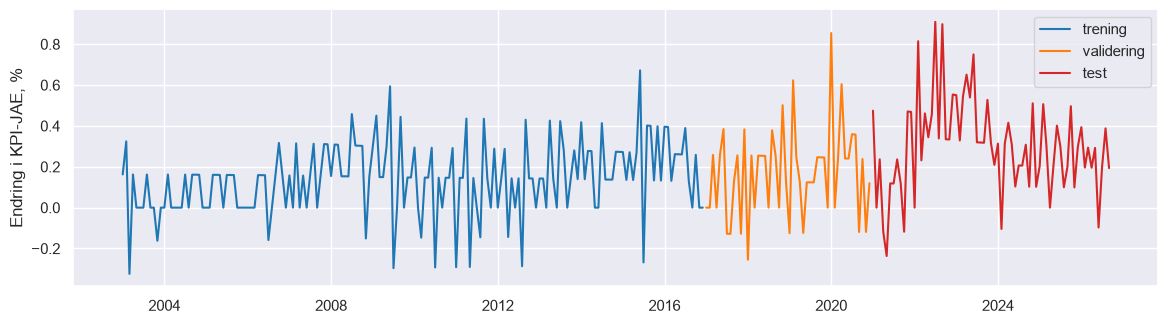

In [81]:
RATES = ["NAV.HL.TOT.PST.S"]
mm = 100 * np.log(raw.drop(columns=RATES)).diff()
mm[RATES] = raw[RATES].diff()

SPLIT = {
    "trening": ("2003-01", "2016-12"),
    "validering": ("2017-01", "2020-12"),
    "test": ("2021-01", "2100-01"),
}
_, ax = plt.subplots(figsize=(14, 3.6))
for (name, (a, b)), c in zip(SPLIT.items(), ["tab:blue", "tab:orange", "tab:red"]):
    s = mm[TARGET].loc[a:b]
    ax.plot(s.index.to_timestamp(), s, color=c, label=name)
ax.set_ylabel("Endring i KPI-JAE, %")
ax.legend()
plt.show()

### Bygge datasettet
Nå bygger vi datasettet. Én rad er én måned $t$:

- $y$ (fasiten): endringen i KPI-JAE måneden etter, $t+1$.
- $X$ (det modellen vet i måned $t$): endringen de 24 siste månedene i KPI-JAE, de 5 driverne og de 53 gruppene (59 serier, 1416 kolonner). Kolonnene heter `serie t-k`: `KPI-JAE t-0` er denne måneden, `KPI-JAE t-1` forrige måned, osv.

Alle kolonnene standardiseres med gjennomsnitt og standardavvik fra treningsperioden, så de er på samme skala. Tall vi mangler (noen serier starter sent), settes til gjennomsnittet.

In [82]:
NAMES = {TARGET: "KPI-JAE", **{v: k for k, v in DRIVERS.items()}}
NAMES |= {
    c: c.replace("MSA_PCPIJAE_25_", "gruppe ")
    .replace("KPI.KPI.25.", "delindeks ")
    .replace(".IPR.S", "")
    for c in GROUPS
}
MAX_LAG = 24  # vi lager 24 måneder tilbake for alle seriene, oppgavene velger hvor mange de bruker

X = pd.concat(
    {
        f"{NAMES[c]} t-{k}": mm[c].shift(k)
        for c in [TARGET, *DRIVERS.values(), *GROUPS]
        for k in range(MAX_LAG)
    },
    axis=1,
)
y = mm[TARGET].shift(-1).rename("KPI-JAE neste måned")

train_part = X.loc[slice(*SPLIT["trening"])]
Z = ((X - train_part.mean()) / train_part.std().replace(0, 1)).fillna(0.0)
ROWS = {name: y.loc[a:b].dropna().index for name, (a, b) in SPLIT.items()}

print(f"X: {X.shape[0]} måneder x {X.shape[1]} kolonner")
print("---")
print({name: len(idx) for name, idx in ROWS.items()}, "måneder i hver del")
print("---")
pd.concat([y, X[["KPI-JAE t-0", "KPI-JAE t-1", "KPI-JAE t-2", "kronekurs t-0", "oljepris t-0", "gruppe K1 t-0"]]], axis=1).loc["2026"].round(2)

X: 309 måneder x 1416 kolonner
---
{'trening': 168, 'validering': 48, 'test': 68} måneder i hver del
---


,KPI-JAE neste måned,KPI-JAE t-0,KPI-JAE t-1,KPI-JAE t-2,kronekurs t-0,oljepris t-0,gruppe K1 t-0
2026-01,0.20,0.39,0.30,0.10,-1.08,5.86,0.04
2026-02,0.29,0.20,0.39,0.30,-2.94,6.63,-0.07
2026-03,0.20,0.29,0.20,0.39,-0.95,37.47,-0.34
2026-04,0.29,0.20,0.29,0.20,-1.58,13.64,1.54
2026-05,-0.10,0.29,0.20,0.29,-1.91,-9.15,-0.44
2026-06,0.19,-0.10,0.29,0.20,2.47,-23.55,-0.47
2026-07,0.39,0.19,-0.10,0.29,0.58,-1.46,-0.10
2026-08,0.19,0.39,0.19,-0.10,-1.72,7.70,0.36
2026-09,NaN,0.19,0.39,0.19,-1.11,22.66,1.06


### Velge kolonner
Hver oppgave velger hvilke kolonner i $X$ modellen får se, med `kolonner(...)`. Du gir den navnet på hver serie og hvor mange måneder tilbake du vil ha med:

- `kolonner({"KPI-JAE": 12})` gir `KPI-JAE t-0` til `KPI-JAE t-11`: de 12 siste månedene av KPI-JAE. Det er dataene til en AR(12)-modell.
- `kolonner({"KPI-JAE": 12, "kronekurs": 3})` gir i tillegg kronekursen de 3 siste månedene.
- `grupper=2` tar med alle de 53 gruppene og delindeksene, de 2 siste månedene.

Deretter deler `datasett(kolonner)` dataene i trening, validering og test: `X_train, y_train, X_val, y_val, X_test, y_test`. $X$ er en tabell med én rad per måned og én kolonne per serie og måned tilbake, og $y$ er fasiten, KPI-JAE måneden etter. Det er disse vi sender inn i `train()` og `evaluate()`.

Seriene heter `KPI-JAE`, `kronekurs`, `oljepris`, `importpriser`, `innsatsvarer`, `ledighet`, og `gruppe K1` til `gruppe K13` og `delindeks K011` osv. for gruppene. Maks 24 måneder tilbake.

In [83]:
def kolonner(lags: dict[str, int], grupper: int = 0) -> list[str]:
    """Velg kolonner i X.

    lags: serienavn -> antall måneder tilbake, f.eks. {"KPI-JAE": 12, "kronekurs": 3}.
          3 betyr t-0, t-1 og t-2.
    grupper: antall måneder tilbake for alle 53 gruppene og delindeksene (0 = ingen).

    Returnerer en liste med kolonnenavn, f.eks. ["KPI-JAE t-0", "KPI-JAE t-1", ...].
    """
    lags = lags | {NAMES[g]: grupper for g in GROUPS if grupper}
    for serie, p in lags.items():
        if f"{serie} t-0" not in X:
            raise KeyError(f"Ukjent serie: {serie!r}. Velg blant {list(NAMES.values())[:6]} eller gruppene.")
        if p > MAX_LAG:
            raise ValueError(f"{serie}: maks {MAX_LAG} måneder tilbake")
    return [f"{serie} t-{k}" for serie, p in lags.items() for k in range(p)]


def datasett(cols: list[str]):
    """Del de valgte kolonnene i trening, validering og test.

    Returnerer X_train, y_train, X_val, y_val, X_test, y_test.
    X er standardisert (Z), én rad per måned. y er KPI-JAE måneden etter.
    """
    return tuple(
        df
        for idx in ROWS.values()
        for df in (Z.loc[idx, cols], y.loc[idx])
    )


print("Få navnet på noen kolonner:")
print(kolonner({"KPI-JAE": 3, "kronekurs": 2}))
print("---")

Få navnet på noen kolonner:
['KPI-JAE t-0', 'KPI-JAE t-1', 'KPI-JAE t-2', 'kronekurs t-0', 'kronekurs t-1']
---


### Resultatet av data (dette er det du trenger)

In [84]:
print("Del dem i trening, validering og test:")
X_train, y_train, X_val, y_val, X_test, y_test = datasett(kolonner({"KPI-JAE": 3, "kronekurs": 2}))
print(f"X_train: {X_train.shape}, X_val: {X_val.shape}, X_test: {X_test.shape}")


Del dem i trening, validering og test:
X_train: (168, 5), X_val: (48, 5), X_test: (68, 5)


In [85]:
X_train

,KPI-JAE t-0,KPI-JAE t-1,KPI-JAE t-2,kronekurs t-0,kronekurs t-1
2003-01,0.141136,-0.133636,0.124900,-0.572348,-0.617234
2003-02,1.060279,0.137496,-0.139354,1.447821,-0.567642
2003-03,-2.625271,1.058289,0.132273,2.277857,1.450229
2003-04,0.139638,-2.633878,1.054749,-0.136956,2.279321
2003-05,-0.782496,0.135995,-2.644165,-0.796234,-0.132745
...,...,...,...,...,...
2016-08,-0.046579,1.429662,0.691118,-0.690533,0.160106
2016-09,-0.782496,-0.050557,1.426801,-0.949581,-0.685693
2016-10,0.686485,-0.787795,-0.056123,-1.513902,-0.944446
2016-11,-0.782496,0.683824,-0.794708,0.515696,-1.508125


In [86]:
y_train

2003-01    0.324149
2003-02   -0.324149
2003-03    0.162206
2003-04    0.000000
2003-05    0.000000
             ...   
2016-08    0.000000
2016-09    0.258398
2016-10    0.000000
2016-11    0.000000
2016-12    0.000000
Freq: M, Name: KPI-JAE neste måned, Length: 168, dtype: float64

## Et par hjelpefunksjoner 
Før vi starter med moddellene må vi lage noen hjelpefunksjoner.

In [87]:
# @title Maskinrom: treningsløkka, evaluering og ledertavle { display-mode: "form" }
LEADERBOARD: list[dict] = []

def tensor(df) -> torch.Tensor:
    """Gjør om en pandas-tabell til en PyTorch-tensor (tenk numpy-array) så modellen kan bruke den."""
    return torch.tensor(df.values, dtype=torch.float32)


def train(
    model: nn.Module, # modellen du skal trene
    X_train: pd.DataFrame, # data modellen trenes på
    y_train: pd.Series,
    X_val: pd.DataFrame, # data vi velger beste runde på (early stopping)
    y_val: pd.Series,
    epochs: int = 50, # How mange runder skal du trene datasettet på?
    lr: float = 0.01, # Learning rate eller step size på læringsalgoritmen (se graf over)
    weight_decay: float = 0.0, # Regularisering. større betyr mindre sjangs for overfitting
    seed: int = 0,
):
    """
    Treningsløkka. Vi tar vare på vektene som traff best på valideringsperioden (early stopping).
    Trening av nevrale nett bruker gradient descent som beskrevet over. Her har vi implementert en bare bones variant av den hvis du vil undersøke. Ideen er å regne ut førstederiverte av tapsfunksjonen med hensyn til parameterne og deretter flytte alle parametere littegrann slik at tapet blir litt mindre. Du trenger ikke forstå dette, bare tenk på `train()` som en fit() funksjon.
    """
    torch.manual_seed(seed)
    for m in model.modules():
        if hasattr(m, "reset_parameters"):
            m.reset_parameters()
    xtr, ytr, xva, yva = tensor(X_train), tensor(y_train), tensor(X_val), tensor(y_val)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    hist, best, state = {"trening": [], "validering": []}, float("inf"), None
    for _ in range(epochs):
        model.train()
        opt.zero_grad()
        loss = ((model(xtr).squeeze(-1) - ytr) ** 2).mean()
        loss.backward()
        opt.step()
        model.eval()
        with torch.no_grad():
            val = ((model(xva).squeeze(-1) - yva) ** 2).mean().item()
        hist["trening"].append(loss.item() ** 0.5)
        hist["validering"].append(val**0.5)
        if val < best:
            best, state = val, {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(state)
    model.eval()
    return model, hist

def evaluate(
    name: str,
    model: nn.Module,
    X_train: pd.DataFrame,
    y_train: pd.Series,
    X_val: pd.DataFrame,
    y_val: pd.Series,
    X_test: pd.DataFrame,
    y_test: pd.Series,
    hist: dict | None = None,
) -> None:
    """RMSE i hver periode, en graf av prognosene i testperioden, og en rad på ledertavla."""
    res = {"modell": name, "parametere": sum(p.numel() for p in model.parameters())}
    with torch.no_grad():
        for part, x, yt in [("trening", X_train, y_train), ("validering", X_val, y_val), ("test", X_test, y_test)]:
            res[part] = ((model(tensor(x)).squeeze(-1) - tensor(yt)) ** 2).mean().item() ** 0.5
        res["prognose neste mnd"] = model(tensor(Z[X_test.columns].iloc[[-1]])).item()  # siste kjente måned
        p = model(tensor(X_test)).squeeze(-1).numpy()
    LEADERBOARD.append(res)
    _, axes = plt.subplots(1, 2 if hist else 1, figsize=(14 if hist else 9, 3.6))
    ax = axes[0] if hist else axes
    t = y_test.index.to_timestamp()
    ax.plot(t, y_test.values, color="black", label="Faktisk")
    ax.plot(t, p, color="tab:red", label=name)
    ax.set_title(f"Testperioden: RMSE {res['test']:.3f}")
    ax.set_ylabel("Endring i KPI-JAE, %")
    ax.legend()
    if hist:
        axes[1].plot(hist["trening"], label="Trening")
        axes[1].plot(hist["validering"], label="Validering")
        axes[1].set_title("Treningsløkka: feil per runde")
        axes[1].set_xlabel("Runde")
        axes[1].set_ylabel("RMSE")
        axes[1].set_ylim(0, max(0.6, min(hist["validering"]) * 2))
        axes[1].legend()
    plt.tight_layout()
    plt.show()
    print({k: round(v, 3) if isinstance(v, float) else v for k, v in res.items()})


def leaderboard() -> pd.DataFrame:
    return (
        pd.DataFrame(LEADERBOARD)
        .drop_duplicates("modell", keep="last")
        .sort_values("validering")
        .round(3)
        .reset_index(drop=True)
    )


### Oppgave 0: Enkle baseline modeller
Det er greit å ha en liten ide om hva slags tap vi kan forvente her. Derfor, la oss lage noen enkle, parameterfrie modeller:

- Gjett samme endring som forrige måned
- Gjennomsnitt siste 12 måneder

In [88]:
# Enkle referanser uten parametere
for name, p in {
    "Naiv: samme som forrige måned": mm[TARGET],
    "Snitt siste 12 mnd": mm[TARGET].rolling(12).mean(),
}.items():
    LEADERBOARD.append(
        {
            "modell": name,
            "parametere": 0,
            **{
                k: float(np.sqrt(((p.loc[idx] - y.loc[idx]) ** 2).mean()))
                for k, idx in ROWS.items()
            },
            "prognose neste mnd": float(p.iloc[-1]),
        }
    )
leaderboard()

,modell,parametere,trening,validering,test,prognose neste mnd
0,Snitt siste 12 mnd,0,0.173,0.23,0.223,0.245
1,Naiv: samme som forrige måned,0,0.258,0.35,0.292,0.193


## Oppgave 1: AR-modellen er et nevralt nett med ett lag

SMART har mange AR-modeller: neste måned er en vektet sum av de $P$ siste månedene:

$$\hat{y}_{t+1} = b + w_1 y_t + w_2 y_{t-1} + \dots + w_P y_{t-P+1}$$

I PyTorch skriver vi en modell som en klasse (`nn.Module`) med to deler:
- `__init__`: parameterne, her én vekt $w$ per måned og et konstantledd $b$. `nn.Parameter` betyr «et tall treningen skal justere».
- `forward`: selve likningen, hvordan prognosen regnes ut fra $X$.

Tegnet som et nettverk er det $P$ noder inn og én ut, og vektene er strekene mellom dem. Et nevralt nett med ett lag.

**Prøv:** endre `P` (antall måneder modellen ser tilbake). Hva skjer med testfeilen? Hvilke måneder får mest vekt?

In [89]:
# 1. Data: de P siste månedene av KPI-JAE
P = 12  # @param {type:"slider", min:1, max:24, step:1}
cols_ar = kolonner({"KPI-JAE": P})
X_train, y_train, X_val, y_val, X_test, y_test = datasett(cols_ar)

# 2. Modell: én vekt per måned, pluss et konstantledd
class AR(nn.Module):
    def __init__(self, P: int):
        super().__init__()
        self.w = nn.Parameter(torch.zeros(P))  # w_1 ... w_P
        self.b = nn.Parameter(torch.zeros(1))  # konstantledd

    def forward(self, x):
        return x @ self.w + self.b  # b + w_1 y_t + w_2 y_t-1 + ...


model_ar = AR(P)

model_ar

AR()

In [90]:
# Test modellen på en batch: de 5 første månedene i treningsdataene inn, 5 prognoser ut.
# Før trening er alle vektene 0, så prognosene er 0.
x_batch = tensor(X_train.head(5))
y_pred = model_ar(x_batch)
print("Batch inn:", x_batch.shape, "-> prognoser ut:", y_pred.shape)

y_pred

Batch inn: torch.Size([5, 12]) -> prognoser ut: torch.Size([5])


tensor([0., 0., 0., 0., 0.], grad_fn=<AddBackward0>)

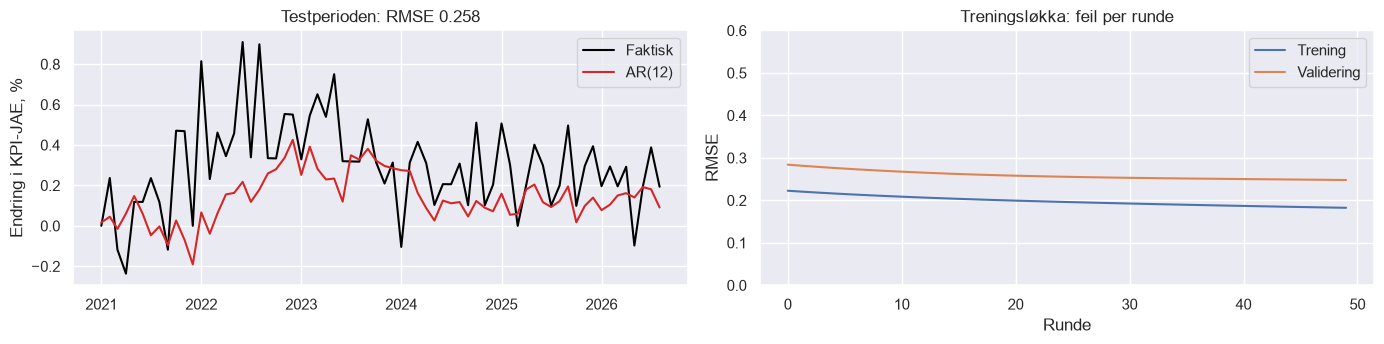

{'modell': 'AR(12)', 'parametere': 13, 'trening': 0.182, 'validering': 0.248, 'test': 0.258, 'prognose neste mnd': 0.01}


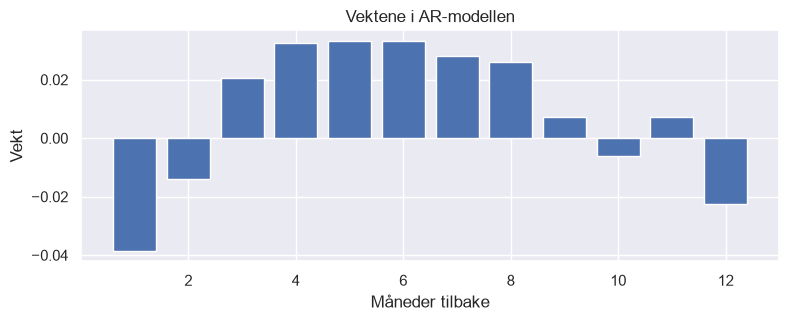

In [91]:
# 3. Trening
model_ar, hist = train(model_ar, X_train, y_train, X_val, y_val, epochs=50, lr=0.001)

# 4. Beslutning: hvor godt traff den, og hva sier den om neste måned?
evaluate(f"AR({P})", model_ar, X_train, y_train, X_val, y_val, X_test, y_test, hist)

# Vektene: hvilke måneder betyr mest?
plt.figure(figsize=(9, 3))
plt.bar(np.arange(1, P + 1), model_ar.w.detach().numpy())
plt.xlabel("Måneder tilbake")
plt.ylabel("Vekt")
plt.title("Vektene i AR-modellen")
plt.show()

#### Tillegg for de som liker analytiske løsninger (ikke nødvendig å lese)
AR-modellen er lineær, så den kan vi også løse med vanlig minste kvadraters metode, *Ordinary Least Squares* (OLS). Da trenger vi ingen treningsløkke, bare en formel:

$$\hat{w} = (X^\top X)^{-1} X^\top y$$

der vi legger til en kolonne med 1-ere i $X$ for konstantleddet. Med nok runder og en passe `lr` ender gradient descent nær det samme svaret. For nevrale nett med skjulte lag finnes det ingen slik formel, og da trenger vi treningsløkka.

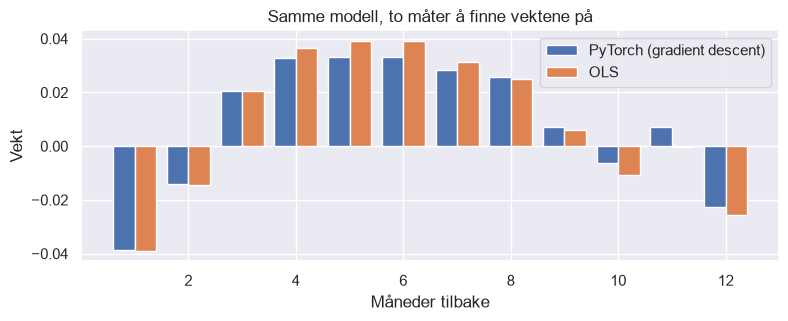

In [92]:
# OLS: løs AR-modellen direkte, uten treningsløkke
X1 = np.column_stack([X_train.values, np.ones(len(X_train))])  # en kolonne med 1-ere for konstantleddet
w_ols = np.linalg.lstsq(X1, y_train.values, rcond=None)[0]

plt.figure(figsize=(9, 3))
plt.bar(np.arange(1, P + 1) - 0.2, model_ar.w.detach().numpy(), width=0.4, label="PyTorch (gradient descent)")
plt.bar(np.arange(1, P + 1) + 0.2, w_ols[:-1], width=0.4, label="OLS")
plt.xlabel("Måneder tilbake")
plt.ylabel("Vekt")
plt.title("Samme modell, to måter å finne vektene på")
plt.legend()
plt.show()

## Oppgave 2: VAR og en prior
Oppgave 1 brukte bare KPI-serien selv for å se hvordan den utviklet seg. Vi vet at andre faktorer påvirker den. Så vi vil gjerne kunne legge de til i X_t for å predikere KPI.

Modellen er i prinsippet det samme, det er en linær modell, men nå på features som ikke bare er tidligere verdier av KPI.

Vi har veldig mange features i datasettet vårt. Hadde vi valgt alle features med alle lags bakover i tid vil vi få mange flere parametere enn vi har datapunkter og risikerer å overfitte modellen veldig mye. Derfor velger vi ut noen flere og også legger på en "weight decay".

En weight decay er en regularisering som "dytter" alle parameterne litt mot null for å motvirke overfitting. I Bayesiansk statistikk er det det samme som en Gaussisk prior mot null.

Prøv med litt forskjellige kolonner, forskjellige antall lags per feature og forskjellig regularisering når du trener for å se hva som fungerer best.

In [93]:
# 1. Data: velg kolonnene direkte. Serienavn -> antall måneder tilbake.
utvalg = {"KPI-JAE": 12, "kronekurs": 3, "oljepris": 3, "importpriser": 3}
# utvalg = {"KPI-JAE": 12, "kronekurs": 3}  # bare kronekursen
# utvalg = {"KPI-JAE": 12, "importpriser": 6, "innsatsvarer": 6}  # prisene bedriftene betaler, et halvt år tilbake
# utvalg = {"KPI-JAE": 12, "kronekurs": 3, "oljepris": 3, "importpriser": 3, "innsatsvarer": 3, "ledighet": 3}  # alle driverne
GRUPPER = 0
# GRUPPER = 2  # også alle 53 gruppene og delindeksene, 2 måneder tilbake: over 100 kolonner, se etter overtilpasning
cols_var = kolonner(utvalg, grupper=GRUPPER)
X_train, y_train, X_val, y_val, X_test, y_test = datasett(cols_var)
print(f"{len(cols_var)} kolonner, {len(X_train)} måneder å trene på")

21 kolonner, 168 måneder å trene på


In [94]:
# 2. Modell: samme som AR, men i stedet for å lage w og b selv bruker vi nn.Linear,
# PyTorch sin ferdige versjon av b + w_1 x_1 + w_2 x_2 + ...
class ARX(nn.Module):
    def __init__(self, n_kolonner: int):
        super().__init__()
        self.lineaer = nn.Linear(n_kolonner, 1)  # n_kolonner vekter (w) og ett konstantledd (b)

    def forward(self, x):
        return self.lineaer(x)


model_var = ARX(len(cols_var))
print(model_var)
print("w:", model_var.lineaer.weight.shape, "b:", model_var.lineaer.bias.shape)


ARX(
  (lineaer): Linear(in_features=21, out_features=1, bias=True)
)
w: torch.Size([1, 21]) b: torch.Size([1])


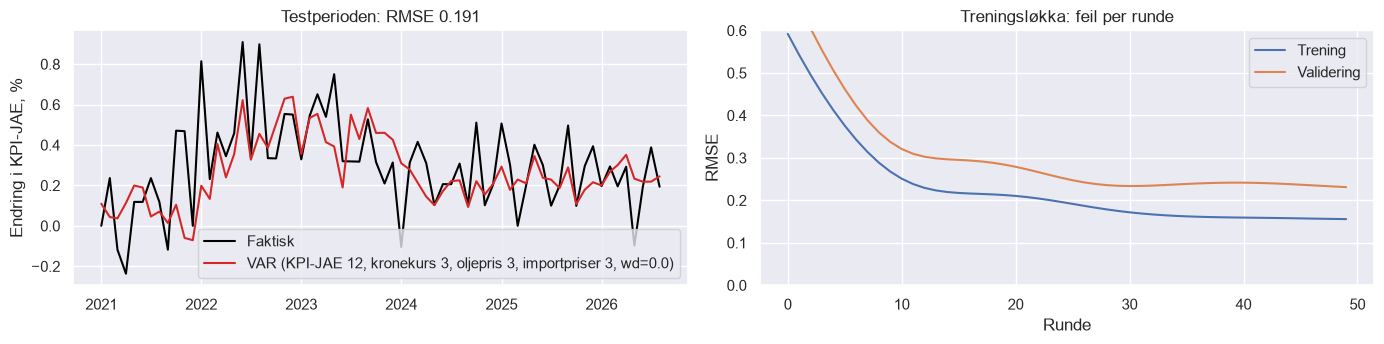

{'modell': 'VAR (KPI-JAE 12, kronekurs 3, oljepris 3, importpriser 3, wd=0.0)', 'parametere': 22, 'trening': 0.156, 'validering': 0.231, 'test': 0.191, 'prognose neste mnd': 0.184}


In [95]:
# 3. Trening: weight decay er prioren som trekker vektene mot null
WEIGHT_DECAY = 0.0  # @param [0.0, 0.01, 0.1, 0.3, 1.0, 3.0] {type:"raw"}
model_var, hist = train(model_var, X_train, y_train, X_val, y_val, weight_decay=WEIGHT_DECAY, epochs=50)

# 4. evaluate
evaluate(
    f"VAR ({', '.join(f'{k} {v}' for k, v in utvalg.items())}{f', grupper {GRUPPER}' if GRUPPER else ''}, wd={WEIGHT_DECAY})",
    model_var,
    X_train, y_train, X_val, y_val, X_test, y_test,
    hist,
)

## Oppgave 3: to lag, en faktormodell

Samme data som i Oppgave 2, men nå med to lag i stedet for ett. Det første laget, `faktorer`, gjør de $n$ kolonnene om til $R$ **faktorer**. Det andre laget, `prognose`, gjør faktorene om til én prognose:

$$f_t = W_1 x_t + b_1 \quad (R \text{ faktorer}), \qquad \hat{y}_{t+1} = w_2^\top f_t + b_2$$

Det er en faktormodell: mange serier komprimeres til noen få faktorer, og vi prognoserer fra dem. Det midterste laget kalles et **skjult lag**, og fordi $R$ er mindre enn $n$ er det en flaskehals. Etter treningen kan vi se på faktorene over tid.

**Prøv:** endre antall faktorer `R`. Hva skjer med valideringsfeilen når `R` blir 1, og når den blir like stor som antall kolonner?

Faktormodell(
  (faktorer): Linear(in_features=21, out_features=3, bias=True)
  (prognose): Linear(in_features=3, out_features=1, bias=True)
)


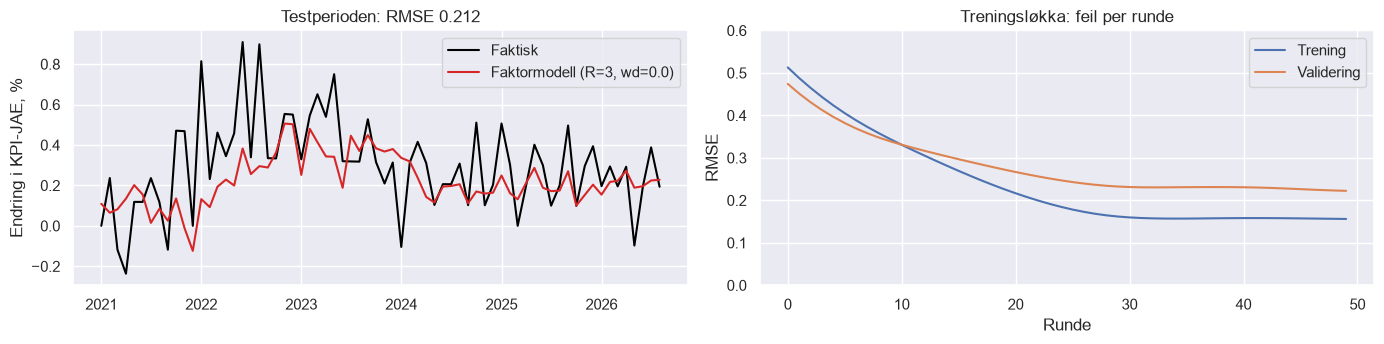

{'modell': 'Faktormodell (R=3, wd=0.0)', 'parametere': 70, 'trening': 0.156, 'validering': 0.222, 'test': 0.212, 'prognose neste mnd': 0.121}


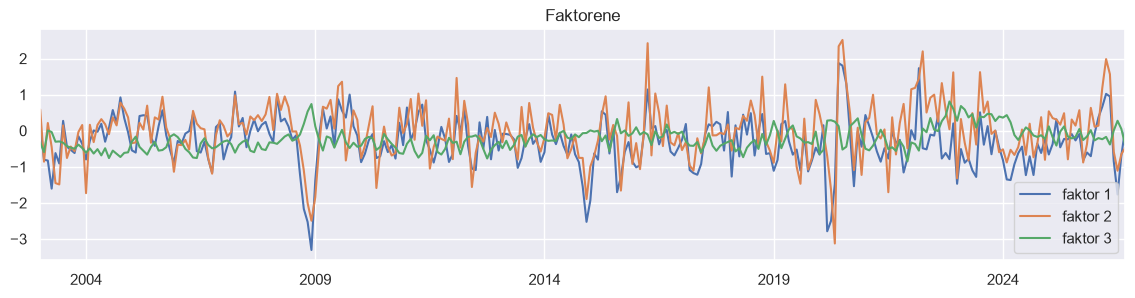

In [96]:
# 1. Data: samme kolonner som i Oppgave 2
X_train, y_train, X_val, y_val, X_test, y_test = datasett(cols_var)

# 2. Modell: to lag. n kolonner -> R faktorer (skjult lag) -> prognose
R = 3  # @param {type:"slider", min:1, max:20, step:1}


class Faktormodell(nn.Module):
    def __init__(self, n_kolonner: int, R: int):
        super().__init__()
        self.faktorer = nn.Linear(n_kolonner, R)  # n kolonner -> R faktorer
        self.prognose = nn.Linear(R, 1)  # R faktorer -> prognose

    def forward(self, x):
        f = self.faktorer(x)
        return self.prognose(f)


model_faktor = Faktormodell(len(cols_var), R)
print(model_faktor)

# 3. Trening
WEIGHT_DECAY_3 = 0.0  # @param [0.0, 0.01, 0.1, 0.3, 1.0, 3.0] {type:"raw"}
model_faktor, hist = train(model_faktor, X_train, y_train, X_val, y_val, lr=0.01, weight_decay=WEIGHT_DECAY_3)

# 4. Beslutning
evaluate(
    f"Faktormodell (R={R}, wd={WEIGHT_DECAY_3})",
    model_faktor,
    X_train, y_train, X_val, y_val, X_test, y_test,
    hist,
)

# Faktorene over tid: hva har modellen lært å se etter?
with torch.no_grad():
    faktorer = model_faktor.faktorer(tensor(Z.loc["2003":, cols_var]))
pd.DataFrame(faktorer.numpy(), index=Z.loc["2003":].index.to_timestamp(), columns=[f"faktor {i + 1}" for i in range(R)]).plot(figsize=(14, 3), title="Faktorene")
plt.show()

## Oppgave 4: slå AR

Ingen av modellene over slår AR-modellen lett. Kan du? Bygg din egen modell under. Alt er lov, men velg modell på **valideringsfeilen**, ikke testfeilen. Ellers jukser du med framtiden.

Snarvei: når lagene bare kommer etter hverandre, kan du bruke `nn.Sequential` i stedet for å skrive en klasse. Det er det samme som en klasse der `forward` sender $X$ gjennom lagene i rekkefølge.

Idéer: færre eller flere lag, bare noen av gruppene, kortere historikk (`p_target`), flere skjulte lag, kombiner prognosene fra flere modeller (som SMART gjør).

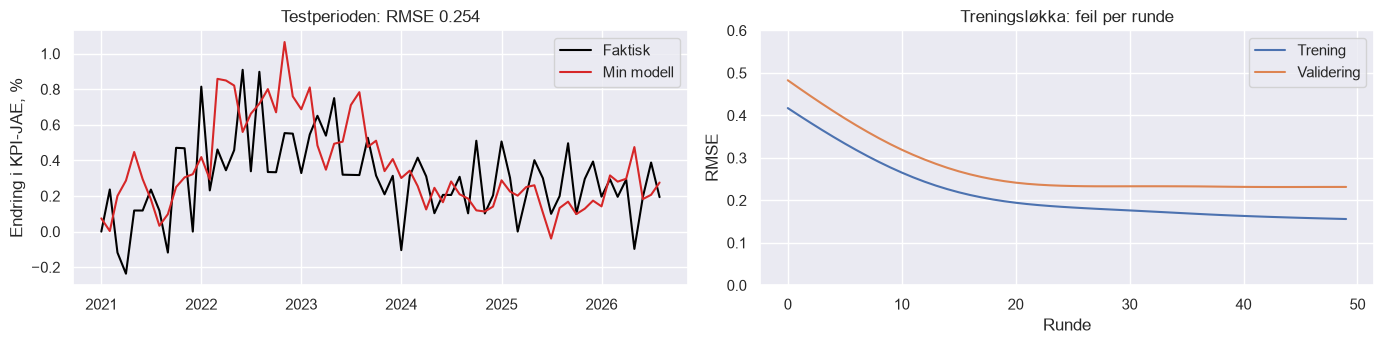

{'modell': 'Min modell', 'parametere': 225, 'trening': 0.16, 'validering': 0.231, 'test': 0.254, 'prognose neste mnd': 0.299}


In [97]:
NAVN = "Min modell"  # @param {type:"string"}

# 1. Data
cols_mine = kolonner({"KPI-JAE": 6, "kronekurs": 3, "importpriser": 3})
X_train, y_train, X_val, y_val, X_test, y_test = datasett(cols_mine)

# 2. Modell: nn.Sequential er en klasse der forward sender x gjennom lagene i rekkefølge
model_mine = nn.Sequential(
    nn.Linear(len(cols_mine), 16),
    nn.ReLU(),
    nn.Linear(16, 1),
)
# 3. Trening
model_mine, hist = train(model_mine, X_train, y_train, X_val, y_val, lr=0.003, weight_decay=0.3)

# 4. Beslutning
evaluate(NAVN, model_mine, X_train, y_train, X_val, y_val, X_test, y_test, hist)

## Oppgave 5: tekst som data

Norges Bank sier mye om inflasjonen før tallene kommer: i taler, foredrag og innledningene på pressekonferansene etter rentemøtene. Kan tekst hjelpe prognosen?

`data/taler.parquet` har alle talene på norges-bank.no siden 1997, én rad per tale:
- `tekst`: hele talen.
- `embedding`: talen som 768 tall fra en embeddingmodell. Taler om det samme får tall som ligner.
- `clef_*`: svar fra **Clef-flash**, en åpen beslutningsmodell. Vi gir den talen og tre spørsmål, og den gir en sannsynlighet for hvert svar: Handler talen om pengepolitikk? Hvordan ser taleren på inflasjonen framover (fra $-2$, klart under målet, til $+2$, klart over)? Hvilket signal gir den om renten (fra $-2$, klart ned, til $+2$, klart opp)?

Det er de samme fire stegene: **data** er tekst, en **modell** (Clef eller embeddingmodellen) gjør teksten om til tall, og så bruker vi tallene som kolonner i $X$.

Fra talene lager vi månedlige kolonner. Er det flere taler i en måned, tar vi snittet, og er det ingen, bruker vi den siste. Da bruker modellen bare det som var sagt innen utgangen av måneden.
- `tale-inflasjon`, `tale-rente`: Clef-svarene, bare fra taler som handler om pengepolitikk.
- `tale-pc1` til `tale-pc20`: de 20 første hovedkomponentene av embeddingene. 768 tall er altfor mye for rundt 170 treningsmåneder.

**Prøv:**
1. Skru på `CLEF`. Blir valideringsfeilen lavere enn for AR(12)?
2. Skru av `CLEF` og øk `ANTALL_PC`. Når begynner modellen å overtilpasse?
3. Se på talene selv: hvilke taler mener Clef er mest «haukete»?

**Pass på framtiden:** språkmodellen bak Clef er trent på tekst fra internett fram til de siste årene. Den kan altså «vite» hva som skjedde etter en gammel tale, selv om vi ber den vurdere bare teksten. Er gevinsten ekte, eller er det en lekkasje?

In [98]:
TALER = "https://raw.githubusercontent.com/simeneide/how-to-train-your-ai/main/data/taler.parquet"
taler = pd.read_parquet(TALER)
print(f"{len(taler)} taler, {taler.dato.min():%Y} til {taler.dato.max():%Y}")

# De fem talene med høyest rentesignal, blant dem som handler om pengepolitikk
taler[taler.clef_pengepolitikk > 0.5].nlargest(5, "clef_rente")[["dato", "tittel", "clef_inflasjon", "clef_rente"]]

412 taler, 1997 til 2026


,dato,tittel,clef_inflasjon,clef_rente
343,2022-04-28 10:15:00,Gjennomføringen av pengepolitikken,1.3672,1.7851
156,2006-05-22 10:00:00,Gjennomføringen av pengepolitikken,-0.7033,1.2146
355,2023-04-05 10:30:00,Vi hever renten for å få prisveksten ned,1.8374,1.2125
175,2007-10-05 08:30:00,Gjennomføringen av pengepolitikken,-0.5912,1.1787
168,2007-02-15 18:00:00,Økonomiske perspektiver,-0.3392,1.1663


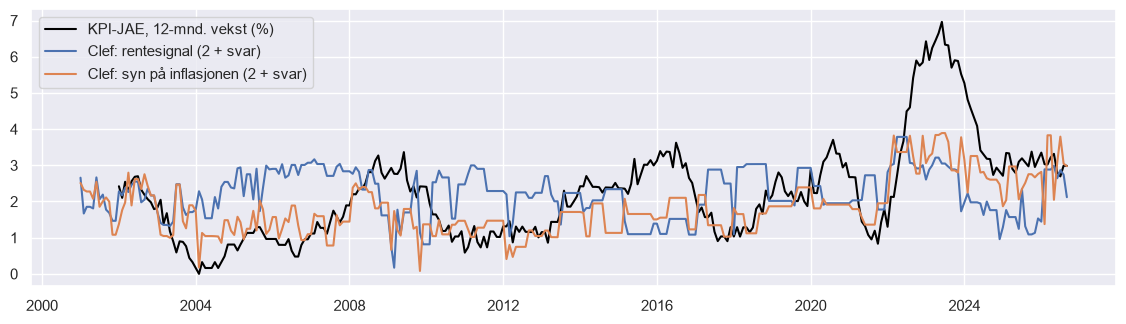

In [99]:
# @title Maskinrom: fra taler til månedlige kolonner i X { display-mode: "form" }
N_PC = 20
maaned = taler.dato.dt.to_period("M")

# Clef-svarene, snitt per måned, bare taler om pengepolitikk
pp = taler.clef_pengepolitikk > 0.5
clef_m = taler[pp].groupby(maaned[pp])[["clef_inflasjon", "clef_rente"]].mean()
clef_m.columns = ["tale-inflasjon", "tale-rente"]

# Embeddingene, snitt per måned, og hovedkomponenter tilpasset bare på treningsmånedene
emb_m = pd.DataFrame(np.stack(taler.embedding), index=maaned).groupby(level=0).mean()
tren = emb_m.loc[slice(*SPLIT["trening"])]
_, _, Vt = np.linalg.svd(tren - tren.mean(), full_matrices=False)
pcs = pd.DataFrame((emb_m - tren.mean()).to_numpy() @ Vt[:N_PC].T, index=emb_m.index)
pcs.columns = [f"tale-pc{i + 1}" for i in range(N_PC)]

# Siste tale videreføres til neste: bare det som var sagt innen utgangen av måneden
tekst = pd.concat([clef_m, pcs], axis=1).reindex(X.index).ffill()

X = X.drop(columns=[c for c in X if c.startswith("tale-")])  # så cellen kan kjøres flere ganger
X = X.join(pd.concat({f"{c} t-{k}": tekst[c].shift(k) for c in tekst for k in range(MAX_LAG)}, axis=1))
train_part = X.loc[slice(*SPLIT["trening"])]
Z = ((X - train_part.mean()) / train_part.std().replace(0, 1)).fillna(0.0)

_, ax = plt.subplots(figsize=(14, 3.6))
ax.plot(raw.index.to_timestamp(), 100 * (raw[TARGET] / raw[TARGET].shift(12) - 1), color="black", label="KPI-JAE, 12-mnd. vekst (%)")
ax.plot(tekst.index.to_timestamp(), 2 + tekst["tale-rente"], label="Clef: rentesignal (2 + svar)")
ax.plot(tekst.index.to_timestamp(), 2 + tekst["tale-inflasjon"], label="Clef: syn på inflasjonen (2 + svar)")
ax.legend()
plt.show()

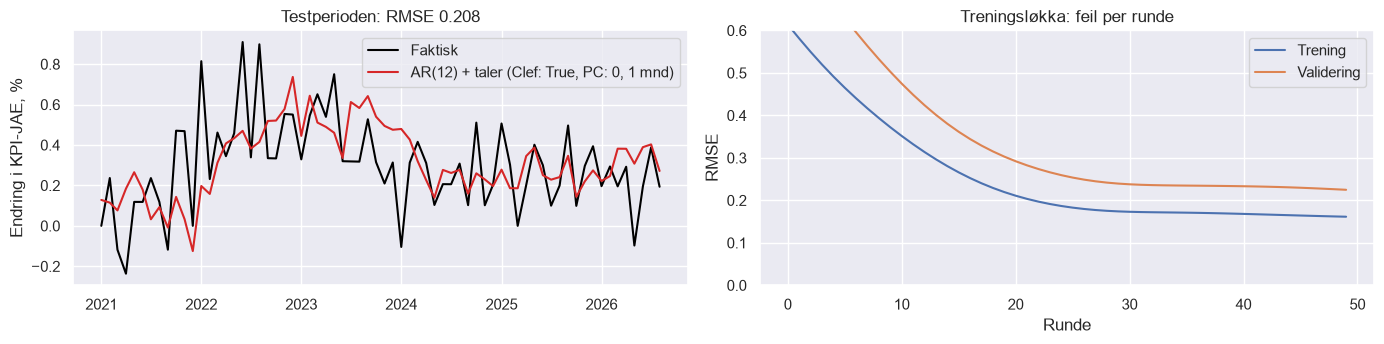

{'modell': 'AR(12) + taler (Clef: True, PC: 0, 1 mnd)', 'parametere': 15, 'trening': 0.161, 'validering': 0.225, 'test': 0.208, 'prognose neste mnd': 0.127}


In [100]:
CLEF = True  # @param {type:"boolean"}
ANTALL_PC = 0  # @param {type:"slider", min:0, max:20, step:1}
MND_TILBAKE = 1  # @param {type:"slider", min:1, max:6, step:1}

# 1. Data: AR(12) pluss talene
tale = {"tale-inflasjon": MND_TILBAKE, "tale-rente": MND_TILBAKE} if CLEF else {}
tale |= {f"tale-pc{i + 1}": MND_TILBAKE for i in range(ANTALL_PC)}
cols_tale = kolonner({"KPI-JAE": 12, **tale})
X_train, y_train, X_val, y_val, X_test, y_test = datasett(cols_tale)

# 2. Modell: lineær, som AR-modellen, bare med flere kolonner
model_tale = nn.Linear(len(cols_tale), 1)

# 3. Trening
model_tale, hist = train(model_tale, X_train, y_train, X_val, y_val)

# 4. Beslutning
evaluate(
    f"AR(12) + taler (Clef: {CLEF}, PC: {ANTALL_PC}, {MND_TILBAKE} mnd)",
    model_tale,
    X_train, y_train, X_val, y_val, X_test, y_test,
    hist,
)

## Ledertavla

Sortert etter valideringsfeil. Den som er best på validering, er den vi ville valgt. Stemmer det med test?

In [101]:
leaderboard()

,modell,parametere,trening,validering,test,prognose neste mnd
0,"Faktormodell (R=3, wd=0.0)",70,0.156,0.222,0.212,0.121
1,"AR(12) + taler (Clef: True, PC: 0, 1 mnd)",15,0.161,0.225,0.208,0.127
2,Snitt siste 12 mnd,0,0.173,0.230,0.223,0.245
3,"VAR (KPI-JAE 12, kronekurs 3, oljepris 3, impo...",22,0.156,0.231,0.191,0.184
4,Min modell,225,0.160,0.231,0.254,0.299
5,AR(12),13,0.182,0.248,0.258,0.010
6,Naiv: samme som forrige måned,0,0.258,0.350,0.292,0.193
